# Etapa 1: Analise Exploratoria dos Dados e Diagnostico (NSL-KDD)

**Disciplina:** Inteligencia Artificial
**Entrega:** 24/10 | **Valor:** 2,00 pontos

Este notebook esta estruturado em 5 frentes de trabalho para divisao entre os 5 membros da equipe:
- **Membro 1:** Caracterizacao Geral da Base e Analise dos Tipos de Dados
- **Membro 2:** Analise das Classes de Ataque e Severidade do Desbalanceamento
- **Membro 3:** Analise dos Atributos Categoricos e Desafio da Alta Cardinalidade
- **Membro 4:** Deteccao de Redundancias, Atributos Constantes e Inconsistencias
- **Membro 5:** Investigacao de Vazamento de Dados (Data Leakage) e Diagnostico Consolidado

In [ ]:
import sys
from pathlib import Path

# Adiciona a raiz do projeto ao path para importar modulos de src
project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise FileNotFoundError("Execute o notebook na raiz do projeto ou em notebooks/.")
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import ALL_COLUMNS, CATEGORICAL_FEATURES, NUMERICAL_FEATURES, ATTACK_MAPPING, CLASSES_5
from src.data_loader import load_raw_dataframe

# Importação para membro 4
from itertools import combinations

sns.set_theme(style="whitegrid")
print("Ambiente e bibliotecas carregados com sucesso.")

Ambiente e bibliotecas carregados com sucesso.


---
## Membro 1 — Caracterização geral da base e análise dos tipos de dados

**Objetivo:** caracterizar a estrutura e a completude do conjunto de treino do NSL-KDD, servindo de base comum para as análises dos demais membros.

**Escopo e cuidados metodológicos**
- Usamos **exclusivamente o `KDDTrain+`**, carregado com `load_raw_dataframe('train')`. O `KDDTest+` não é carregado nem consultado nesta seção, pois está reservado à avaliação final (seção 3 do enunciado). Assim, nenhuma informação do teste influencia o diagnóstico, evitando *data leakage*.
- Todas as colunas são preservadas, incluindo `label` e `difficulty_level`, porque esta etapa é diagnóstica.
- Aqui apenas **diagnosticamos e propomos**. A implementação e a comparação das técnicas de pré-processamento ficam para a Etapa 2.

### 1.1 Carregamento do conjunto de treino bruto

In [151]:
# Opções de exibição usadas nesta seção
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# load_raw_dataframe (src.data_loader) já foi importado na célula de setup do notebook.
# Lê data/raw/KDDTrain+.txt com as 43 colunas nomeadas conforme src.config.ALL_COLUMNS.
df_train = load_raw_dataframe("train")
df_train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,150,25,0.1700,0.0300,0.1700,0.0000,0.0000,0.0000,0.0500,0.0000,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0000,0.0000,0.0000,0.0000,0.0800,0.1500,0.0000,255,1,0.0000,0.6000,0.8800,0.0000,0.0000,0.0000,0.0000,0.0000,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0000,1.0000,0.0000,0.0000,0.0500,0.0700,0.0000,255,26,0.1000,0.0500,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2000,0.2000,0.0000,0.0000,1.0000,0.0000,0.0000,30,255,1.0000,0.0000,0.0300,0.0400,0.0300,0.0100,0.0000,0.0100,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0900,255,255,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,normal,21


### 1.2 Dimensões e papel de cada coluna

In [152]:
COL_ROTULO = "label"
COL_METADADO = "difficulty_level"
COLS_ATRIBUTOS = [c for c in df_train.columns if c not in (COL_ROTULO, COL_METADADO)]

n_linhas, n_colunas = df_train.shape

# Verificações automáticas da estrutura esperada (41 atributos + label + difficulty_level)
assert n_colunas == 43, f"Esperadas 43 colunas, encontradas {n_colunas}"
assert len(COLS_ATRIBUTOS) == 41, f"Esperados 41 atributos, encontrados {len(COLS_ATRIBUTOS)}"

estrutura = pd.DataFrame({
    "Grupo": ["Atributos descritivos", "Rótulo (label)", "Metadado (difficulty_level)", "Total de colunas"],
    "Quantidade": [len(COLS_ATRIBUTOS), 1, 1, n_colunas],
})
print(f"Instâncias (linhas): {n_linhas:,}")
print(f"Colunas: {n_colunas}")
print(f"Uso de memória: {df_train.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
estrutura

Instâncias (linhas): 125,973
Colunas: 43
Uso de memória: 63.1 MB


,Grupo,Quantidade
0,Atributos descritivos,41
1,Rótulo (label),1
2,Metadado (difficulty_level),1
3,Total de colunas,43


In [153]:
# Visão rápida das duas colunas que NÃO são atributos descritivos
print(f"label: tipo {df_train[COL_ROTULO].dtype}, {df_train[COL_ROTULO].nunique()} valores distintos "
      f"(normal + tipos de ataque)")
print(f"difficulty_level: tipo {df_train[COL_METADADO].dtype}, "
      f"intervalo [{df_train[COL_METADADO].min()}, {df_train[COL_METADADO].max()}], "
      f"{df_train[COL_METADADO].nunique()} valores distintos")
# difficulty_level é um metadado criado pelos autores da base (quantos classificadores de referência
# acertaram o registro). Ele NÃO é uma característica do tráfego e não deve ser usado como entrada
# do modelo. É mantido aqui apenas para o diagnóstico.

label: tipo str, 23 valores distintos (normal + tipos de ataque)
difficulty_level: tipo int64, intervalo [0, 21], 22 valores distintos


### 1.3 Mapeamento dos tipos dos atributos

Distinguimos dois níveis:
- **Tipo físico:** como o pandas armazenou a coluna (inteiro, real ou texto).
- **Tipo semântico:** o que o valor representa (categórico, binário, contagem inteira, taxa real). Isso importa porque um atributo armazenado como inteiro pode ser, na prática, uma variável binária ou categórica, e o tratamento na Etapa 2 depende dessa leitura.

In [154]:
def tipo_fisico(serie: pd.Series) -> str:
    if pd.api.types.is_integer_dtype(serie):
        return "inteiro"
    if pd.api.types.is_float_dtype(serie):
        return "real"
    return "categórico (texto)"

def tipo_semantico(serie: pd.Series) -> str:
    # Regras derivadas dos próprios valores observados
    if not pd.api.types.is_numeric_dtype(serie):
        return "categórico nominal"
    valores = set(serie.unique())
    if len(valores) == 1:
        return "constante"
    if valores <= {0, 1}:
        return "binário (0/1)"
    if pd.api.types.is_float_dtype(serie) and serie.min() >= 0 and serie.max() <= 1:
        return "real – taxa em [0, 1]"
    if pd.api.types.is_integer_dtype(serie):
        return "inteiro – contagem/magnitude"
    return "real"

mapa_tipos = pd.DataFrame({
    "dtype_pandas": df_train[COLS_ATRIBUTOS].dtypes.astype(str),
    "tipo_fisico": [tipo_fisico(df_train[c]) for c in COLS_ATRIBUTOS],
    "tipo_semantico": [tipo_semantico(df_train[c]) for c in COLS_ATRIBUTOS],
    "n_valores_distintos": df_train[COLS_ATRIBUTOS].nunique(),
})
mapa_tipos

,dtype_pandas,tipo_fisico,tipo_semantico,n_valores_distintos
duration,int64,inteiro,inteiro – contagem/magnitude,2981
protocol_type,str,categórico (texto),categórico nominal,3
service,str,categórico (texto),categórico nominal,70
flag,str,categórico (texto),categórico nominal,11
src_bytes,int64,inteiro,inteiro – contagem/magnitude,3341
dst_bytes,int64,inteiro,inteiro – contagem/magnitude,9326
land,int64,inteiro,binário (0/1),2
wrong_fragment,int64,inteiro,inteiro – contagem/magnitude,3
urgent,int64,inteiro,inteiro – contagem/magnitude,4
hot,int64,inteiro,inteiro – contagem/magnitude,28


In [155]:
# Resumo: quantos atributos em cada tipo físico e semântico
resumo_fisico = mapa_tipos["tipo_fisico"].value_counts().rename("qtd_atributos")
resumo_semantico = mapa_tipos["tipo_semantico"].value_counts().rename("qtd_atributos")
display(resumo_fisico.to_frame())
display(resumo_semantico.to_frame())

COLS_CATEGORICAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "categórico (texto)"].tolist()
COLS_INTEIRAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "inteiro"].tolist()
COLS_REAIS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "real"].tolist()
COLS_NUMERICAS = COLS_INTEIRAS + COLS_REAIS

print("Categóricos:", COLS_CATEGORICAS)
print(f"Inteiros ({len(COLS_INTEIRAS)}):", COLS_INTEIRAS)
print(f"Reais ({len(COLS_REAIS)}):", COLS_REAIS)

,qtd_atributos
tipo_fisico,
inteiro,23
real,15
categórico (texto),3


,qtd_atributos
tipo_semantico,
inteiro – contagem/magnitude,17
"real – taxa em [0, 1]",15
binário (0/1),5
categórico nominal,3
constante,1


Categóricos: ['protocol_type', 'service', 'flag']
Inteiros (23): ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'dst_host_count', 'dst_host_srv_count']
Reais (15): ['serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


In [156]:
# Atributos inteiros que, pela documentação do NSL-KDD, são binários (sim/não).
# Verificamos se os valores observados respeitam esse domínio.
BINARIOS_DOCUMENTADOS = ["land", "logged_in", "root_shell", "su_attempted",
                         "is_host_login", "is_guest_login"]

verif_binarios = pd.DataFrame({
    "valores_observados": [sorted(df_train[c].unique().tolist()) for c in BINARIOS_DOCUMENTADOS],
    "frequencia_valor_1": [(df_train[c] == 1).sum() for c in BINARIOS_DOCUMENTADOS],
    "dominio_0_1_respeitado": [set(df_train[c].unique()) <= {0, 1} for c in BINARIOS_DOCUMENTADOS],
}, index=BINARIOS_DOCUMENTADOS)
verif_binarios

,valores_observados,frequencia_valor_1,dominio_0_1_respeitado
land,"[0, 1]",25,True
logged_in,"[0, 1]",49852,True
root_shell,"[0, 1]",169,True
su_attempted,"[0, 1, 2]",21,False
is_host_login,"[0, 1]",1,True
is_guest_login,"[0, 1]",1187,True


In [157]:
# Cardinalidade dos atributos categóricos (relevante para a escolha da codificação na Etapa 2)
card = pd.DataFrame({
    "n_categorias": df_train[COLS_CATEGORICAS].nunique(),
    "categoria_mais_frequente": [df_train[c].mode()[0] for c in COLS_CATEGORICAS],
    "pct_mais_frequente": [df_train[c].value_counts(normalize=True).iloc[0] * 100 for c in COLS_CATEGORICAS],
    "categorias_com_<10_registros": [(df_train[c].value_counts() < 10).sum() for c in COLS_CATEGORICAS],
})
card

,n_categorias,categoria_mais_frequente,pct_mais_frequente,categorias_com_<10_registros
protocol_type,3,tcp,81.5167,0
service,70,http,32.0211,8
flag,11,SF,59.4929,0


### 1.4 Valores ausentes

In [158]:
# (a) Ausentes explícitos (NaN/None) por coluna, em todas as 43 colunas
ausentes = pd.DataFrame({
    "n_ausentes": df_train.isna().sum(),
    "pct_ausentes": df_train.isna().mean() * 100,
})
print(f"Colunas com pelo menos um ausente: {(ausentes['n_ausentes'] > 0).sum()} de {n_colunas}")
print(f"Total de células ausentes: {int(ausentes['n_ausentes'].sum()):,} "
      f"de {df_train.size:,} células ({ausentes['n_ausentes'].sum() / df_train.size * 100:.4f}%)")
print(f"Linhas com pelo menos um ausente: {df_train.isna().any(axis=1).sum():,}")
ausentes.T

Colunas com pelo menos um ausente: 0 de 43
Total de células ausentes: 0 de 5,416,839 células (0.0000%)
Linhas com pelo menos um ausente: 0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level
n_ausentes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
pct_ausentes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [159]:
# (b) Ausentes "disfarçados": marcadores que não viram NaN na leitura do arquivo.
# Em bases de rede é comum usar '?', '-', strings vazias ou valores negativos como "sem informação".
MARCADORES_TEXTO = {"?", "-", "", "na", "n/a", "nan", "null", "none"}
colunas_texto = COLS_CATEGORICAS + [COL_ROTULO]

marcadores = {
    c: df_train[c].astype(str).str.strip().str.lower().isin(MARCADORES_TEXTO).sum()
    for c in colunas_texto
}
negativos = (df_train[COLS_NUMERICAS + [COL_METADADO]] < 0).sum()

print("Marcadores textuais de ausência nas colunas categóricas/rótulo:", marcadores)
print("Colunas numéricas com valores negativos:", int((negativos > 0).sum()))

Marcadores textuais de ausência nas colunas categóricas/rótulo: {'protocol_type': 0, 'service': 0, 'flag': 0, 'label': 0}
Colunas numéricas com valores negativos: 0


### 1.5 Estatísticas descritivas dos atributos numéricos

Além de média, desvio padrão e quartis, incluímos o coeficiente de variação, a assimetria e a proporção de zeros, que ajudam a justificar as propostas de transformação da Etapa 2.

In [160]:
desc = df_train[COLS_NUMERICAS].describe().T  # count, mean, std, min, 25%, 50%, 75%, max
desc["cv"] = desc["std"] / desc["mean"].replace(0, np.nan)        # dispersão relativa
desc["assimetria"] = df_train[COLS_NUMERICAS].skew()
desc["pct_zeros"] = (df_train[COLS_NUMERICAS] == 0).mean() * 100
desc.insert(0, "tipo", mapa_tipos.loc[COLS_NUMERICAS, "tipo_semantico"])
desc

,tipo,count,mean,std,min,25%,50%,75%,max,cv,assimetria,pct_zeros
duration,inteiro – contagem/magnitude,"125,973.0000",287.1447,"2,604.5153",0.0000,0.0000,0.0000,0.0000,"42,908.0000",9.0704,11.8802,92.0475
src_bytes,inteiro – contagem/magnitude,"125,973.0000","45,566.7430","5,870,331.1819",0.0000,0.0000,44.0000,276.0000,"1,379,963,888.0000",128.8293,190.6693,39.2084
dst_bytes,inteiro – contagem/magnitude,"125,973.0000","19,779.1144","4,021,269.1514",0.0000,0.0000,0.0000,516.0000,"1,309,937,401.0000",203.3089,290.0529,53.9536
land,binário (0/1),"125,973.0000",0.0002,0.0141,0.0000,0.0000,0.0000,0.0000,1.0000,70.9786,70.9651,99.9802
wrong_fragment,inteiro – contagem/magnitude,"125,973.0000",0.0227,0.2535,0.0000,0.0000,0.0000,0.0000,3.0000,11.1749,11.4580,99.1347
urgent,inteiro – contagem/magnitude,"125,973.0000",0.0001,0.0144,0.0000,0.0000,0.0000,0.0000,3.0000,129.2665,149.9145,99.9929
hot,inteiro – contagem/magnitude,"125,973.0000",0.2044,2.1500,0.0000,0.0000,0.0000,0.0000,77.0000,10.5180,12.5899,97.8797
num_failed_logins,inteiro – contagem/magnitude,"125,973.0000",0.0012,0.0452,0.0000,0.0000,0.0000,0.0000,5.0000,37.0059,53.7644,99.9032
logged_in,binário (0/1),"125,973.0000",0.3957,0.4890,0.0000,0.0000,0.0000,1.0000,1.0000,1.2357,0.4264,60.4264
num_compromised,inteiro – contagem/magnitude,"125,973.0000",0.2793,23.9420,0.0000,0.0000,0.0000,0.0000,"7,479.0000",85.7368,250.1079,98.9791


In [161]:
# Destaques objetivos extraídos da tabela acima
print("Atributos com desvio padrão zero (constantes):",
      desc.index[desc["std"] == 0].tolist())
print("\nAtributos com mediana = 0 e Q3 = 0 (mais de 75% de zeros):")
print(desc.index[(desc["50%"] == 0) & (desc["75%"] == 0)].tolist())
print("\nMaiores amplitudes (max - min):")
print((desc["max"] - desc["min"]).sort_values(ascending=False).head(5).apply(lambda v: f"{v:,.0f}"))
print("\nAtributos com |assimetria| > 10:")
print(desc.loc[desc["assimetria"].abs() > 10, "assimetria"].sort_values(ascending=False).round(1))

Atributos com desvio padrão zero (constantes): ['num_outbound_cmds']

Atributos com mediana = 0 e Q3 = 0 (mais de 75% de zeros):
['duration', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'rerror_rate', 'srv_rerror_rate', 'srv_diff_host_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Maiores amplitudes (max - min):
src_bytes          1,379,963,888
dst_bytes          1,309,937,401
duration                  42,908
num_compromised            7,479
num_root                   7,468
dtype: str

Atributos com |assimetria| > 10:
is_host_login        354.9000
dst_bytes            290.1000
num_compromised      250.1000
num_root             236.9000
src_bytes            190.7000
urgent               149.9000
land                  71.0000
num_shells            59.6000
num_file_creations    55.7000


### 1.6 Observações estruturais para os demais membros

Verificação rápida de redundância e conflito de rótulos. Não tratamos nada aqui: os números servem de ponto de partida para quem analisar dados redundantes/inconsistentes.

In [162]:
dup_total = df_train.duplicated().sum()
dup_sem_dificuldade = df_train.drop(columns=[COL_METADADO]).duplicated().sum()

# Registros com os mesmos 41 atributos, mas rótulos diferentes (inconsistência de rótulo)
grupos = df_train.groupby(COLS_ATRIBUTOS, dropna=False)[COL_ROTULO].nunique()
grupos_conflitantes = grupos[grupos > 1]
linhas_conflitantes = df_train.merge(
    grupos_conflitantes.reset_index()[COLS_ATRIBUTOS], on=COLS_ATRIBUTOS, how="inner"
)

print(f"Linhas duplicadas (43 colunas): {dup_total}")
print(f"Linhas duplicadas ignorando difficulty_level: {dup_sem_dificuldade}")
print(f"Grupos de atributos idênticos com rótulos diferentes: {len(grupos_conflitantes)} "
      f"({len(linhas_conflitantes)} linhas envolvidas)")
(linhas_conflitantes
 .sort_values(["protocol_type", "service", "flag", "src_bytes", COL_ROTULO])
 [["protocol_type", "service", "flag", "src_bytes", "dst_bytes", COL_ROTULO, COL_METADADO]]
 .head(12))

Linhas duplicadas (43 colunas): 0
Linhas duplicadas ignorando difficulty_level: 0
Grupos de atributos idênticos com rótulos diferentes: 15 (31 linhas envolvidas)


,protocol_type,service,flag,src_bytes,dst_bytes,label,difficulty_level
8,icmp,eco_i,SF,8,0,ipsweep,13
10,icmp,eco_i,SF,8,0,ipsweep,16
19,icmp,eco_i,SF,8,0,ipsweep,15
21,icmp,eco_i,SF,8,0,ipsweep,16
1,icmp,eco_i,SF,8,0,nmap,16
6,icmp,eco_i,SF,8,0,nmap,13
12,icmp,eco_i,SF,8,0,nmap,15
30,icmp,eco_i,SF,8,0,nmap,16
7,icmp,ecr_i,SF,8,0,ipsweep,5
20,icmp,ecr_i,SF,8,0,ipsweep,6


### 1.7 Síntese: dimensões, tipos e completude

**Dimensões.** O `KDDTrain+` tem **125.973 instâncias e 43 colunas**: 41 atributos descritivos, o rótulo `label` (23 valores distintos: `normal` e 22 tipos de ataque) e o metadado `difficulty_level` (inteiro de 0 a 21). O `difficulty_level` descreve a dificuldade de classificação atribuída pelos autores da base, não o tráfego em si. Por isso, deve ser **excluído das entradas do modelo** na Etapa 2, pois usá-lo seria uma forma de vazamento de informação sobre o próprio rótulo.

**Tipos.** Pelo armazenamento, os 41 atributos se dividem em **23 inteiros, 15 reais e 3 categóricos** (`protocol_type`, `service`, `flag`). A leitura semântica, porém, é mais fina:
- Os 15 reais são todos **taxas no intervalo [0, 1]** (ex.: `serror_rate`, `same_srv_rate`), já em escala comparável entre si.
- Entre os inteiros, 5 são **binários** (`land`, `logged_in`, `root_shell`, `is_host_login`, `is_guest_login`), 17 são **contagens/magnitudes** e 1 é **constante**.
- `su_attempted`, documentado como binário, assume os valores **{0, 1, 2}**. É uma inconsistência de domínio a ser tratada (por exemplo, mapear 2 → 1) e discutida por quem analisar dados inconsistentes.
- Os categóricos têm cardinalidades muito diferentes: `protocol_type` tem 3 categorias, `flag` tem 11 e `service` tem **70**, das quais 8 aparecem menos de 10 vezes. Isso antecipa a discussão da conversão simbólico-numérica: *one-hot* em `service` gera ~70 colunas esparsas, o que motiva comparar com alternativas (agrupar categorias raras, *frequency* ou *target encoding* ajustados apenas dentro de cada *fold* de treino).

**Completude.** **Não há valores ausentes**: 0 de 5.416.839 células, em todas as 43 colunas. Também não foram encontrados ausentes disfarçados (`?`, `-`, strings vazias) nem valores negativos. Portanto, **não há necessidade de imputação** no treino. Como precaução, o pipeline da Etapa 2 pode manter um imputador ajustado só no treino, caso surjam ausentes em dados futuros.

**Distribuições numéricas.** As estatísticas mostram atributos fortemente assimétricos e dominados por zeros:
- `num_outbound_cmds` tem desvio padrão zero (constante) e não traz informação. É candidato direto à remoção.
- 21 atributos têm mediana e Q3 iguais a zero, isto é, mais de 75% dos registros valem 0 (ex.: `duration` vale 0 em 92% dos casos).
- `src_bytes` e `dst_bytes` vão de 0 a cerca de 1,3–1,4 bilhão, com desvio padrão na casa dos milhões e assimetria acima de 190. Já as taxas estão limitadas a [0, 1] e `dst_host_count` a 255.

Essa diferença de escalas de várias ordens de grandeza justifica, na Etapa 2, testar uma transformação como `log1p` nos atributos de bytes e contagens, seguida de normalização (`StandardScaler` ou `MinMaxScaler`), **sempre ajustada apenas no treino** (dentro da validação cruzada) e aplicada depois ao teste.

**Observações para os demais membros.** Não há linhas duplicadas, nem considerando todas as colunas, nem ignorando `difficulty_level`, o que confirma a limpeza feita pelos autores do NSL-KDD. Porém existem **15 grupos de registros com os mesmos 41 atributos e rótulos diferentes (31 linhas)**. Dez desses grupos são tráfego ICMP. Em 8 grupos o conflito é só entre ataques de varredura (`ipsweep`, `nmap`, `portsweep`), e nos outros 7 um registro `normal` aparece com o mesmo vetor de atributos de um ataque (`satan`, `pod`, `rootkit` e, em 4 grupos de `tcp/finger`, `land`). Esses conflitos são o ponto de partida para a análise de dados inconsistentes.

---
## Membro 2 — Classes de ataque e severidade do desbalanceamento

**Escopo da entrega de 24/10 (2,00 pontos).** Identificar os rótulos originais, quantificar o desbalanceamento e apresentar um breve diagnóstico, conforme a seção 10 do enunciado. Reutilizamos exclusivamente `df_train`, carregado na seção 1.1 com `load_raw_dataframe('train')`. O `KDDTest+` permanece reservado à avaliação final (seção 3).

A análise principal usa os **rótulos originais de `label`**. As cinco famílias (`normal`, `dos`, `probe`, `r2l`, `u2r`) são uma **análise complementar**, obtida com `src.config.ATTACK_MAPPING`. O enunciado menciona U2R como exemplo de classe rara (seção 2.1), mas **não define explicitamente um agrupamento obrigatório em cinco classes**. A existência desse mapeamento no projeto não confirma o alvo oficial da competição.

### 2.1 Rótulos originais: identificação e frequências

Os percentuais abaixo usam todas as linhas do treino como denominador. Nenhum rótulo é substituído e nenhum registro é removido ou reamostrado.

In [163]:
# Trabalha em uma cópia apenas do rótulo. df_train mantém suas 43 colunas originais.
df_classes = df_train[["label"]].copy()
rotulos_originais = df_train["label"].copy(deep=True)
n_treino = len(df_classes)

assert n_treino > 0, "O conjunto de treino está vazio."
assert df_classes["label"].notna().all(), "Há rótulos ausentes no treino."
rotulos_observados = sorted(df_classes["label"].unique())
tipos_ataque = [rotulo for rotulo in rotulos_observados if rotulo != "normal"]
assert "normal" in rotulos_observados, "Rótulo normal não encontrado."
assert len(rotulos_observados) == 23, f"Esperados 23 rótulos, encontrados {len(rotulos_observados)}."
assert len(tipos_ataque) == 22, f"Esperados 22 tipos de ataque, encontrados {len(tipos_ataque)}."

print(f"Treino: {n_treino:,} registros, {len(rotulos_observados)} rótulos = "
      f"{len(tipos_ataque)} tipos de ataque + normal.")
print("Rótulos originais:", ", ".join(rotulos_observados))


def tabela_frequencias(serie):
    """Conta cada categoria e calcula seu percentual sobre todas as linhas recebidas."""
    tabela = serie.value_counts(dropna=False).rename("frequencia").to_frame()
    tabela["percentual"] = 100 * tabela["frequencia"] / len(serie)
    assert tabela["frequencia"].sum() == len(serie), "Perda de registros na contagem."
    assert np.isclose(tabela["percentual"].sum(), 100), "Percentuais não somam 100%."
    return tabela


freq_rotulos = tabela_frequencias(df_classes["label"])
display(freq_rotulos)

Treino: 125,973 registros, 23 rótulos = 22 tipos de ataque + normal.
Rótulos originais: back, buffer_overflow, ftp_write, guess_passwd, imap, ipsweep, land, loadmodule, multihop, neptune, nmap, normal, perl, phf, pod, portsweep, rootkit, satan, smurf, spy, teardrop, warezclient, warezmaster


,frequencia,percentual
label,,
normal,67343,53.4583
neptune,41214,32.7165
satan,3633,2.8840
ipsweep,3599,2.8570
portsweep,2931,2.3267
smurf,2646,2.1005
nmap,1493,1.1852
back,956,0.7589
teardrop,892,0.7081


### 2.2 Cinco famílias: derivação e cobertura do mapeamento

Criamos `attack_family` somente em `df_classes`, mantendo `label` intacta. Essa coluna é derivada do rótulo e **não deve ser usada como atributo preditivo**. A checagem de cobertura interrompe a execução se qualquer rótulo do treino não estiver mapeado. Rótulos desconhecidos não são descartados nem convertidos silenciosamente para `normal`.

In [164]:
# Verifica todos os rótulos observados antes de usar as frequências agrupadas.
rotulos_sem_mapeamento = sorted(set(rotulos_observados) - set(ATTACK_MAPPING))
print("Rótulos sem mapeamento:", rotulos_sem_mapeamento)
assert not rotulos_sem_mapeamento, f"Revisar ATTACK_MAPPING: {rotulos_sem_mapeamento}"

df_classes["attack_family"] = df_classes["label"].map(ATTACK_MAPPING)
assert df_classes["attack_family"].notna().all(), "O mapeamento gerou valores ausentes."
assert set(df_classes["attack_family"].unique()) == set(CLASSES_5), "Famílias inesperadas."
pd.testing.assert_series_equal(df_classes["label"], rotulos_originais)
pd.testing.assert_series_equal(df_train["label"], rotulos_originais)
assert "attack_family" not in df_train.columns, "A coluna derivada não deve alterar df_train."

freq_familias = tabela_frequencias(df_classes["attack_family"]).reindex(CLASSES_5)
assert freq_familias["frequencia"].sum() == n_treino
print(f"Cobertura: {df_classes['attack_family'].notna().sum():,}/{n_treino:,} registros.")
display(freq_familias)

# Expõe quais rótulos originais compõem a família mais rara.
rotulos_u2r = [r for r in rotulos_observados if ATTACK_MAPPING[r] == "u2r"]
print("Composição de u2r (percentuais em relação ao treino inteiro):")
display(freq_rotulos.loc[rotulos_u2r].sort_values("frequencia", ascending=False))

Rótulos sem mapeamento: []
Cobertura: 125,973/125,973 registros.


,frequencia,percentual
attack_family,,
normal,67343,53.4583
dos,45927,36.4578
probe,11656,9.2528
r2l,995,0.7899
u2r,52,0.0413


Composição de u2r (percentuais em relação ao treino inteiro):


,frequencia,percentual
label,,
buffer_overflow,30,0.0238
rootkit,10,0.0079
loadmodule,9,0.0071
perl,3,0.0024


### 2.3 Distribuições originais e agrupadas

Cada figura apresenta as mesmas contagens em duas escalas. A escala **linear**, com origem em zero, evidencia a concentração. A escala **logarítmica** permite enxergar as categorias raras e comparar ordens de grandeza. Na escala logarítmica, comprimentos não representam proporções lineares. As anotações informam a frequência absoluta e o percentual sobre todo o treino.

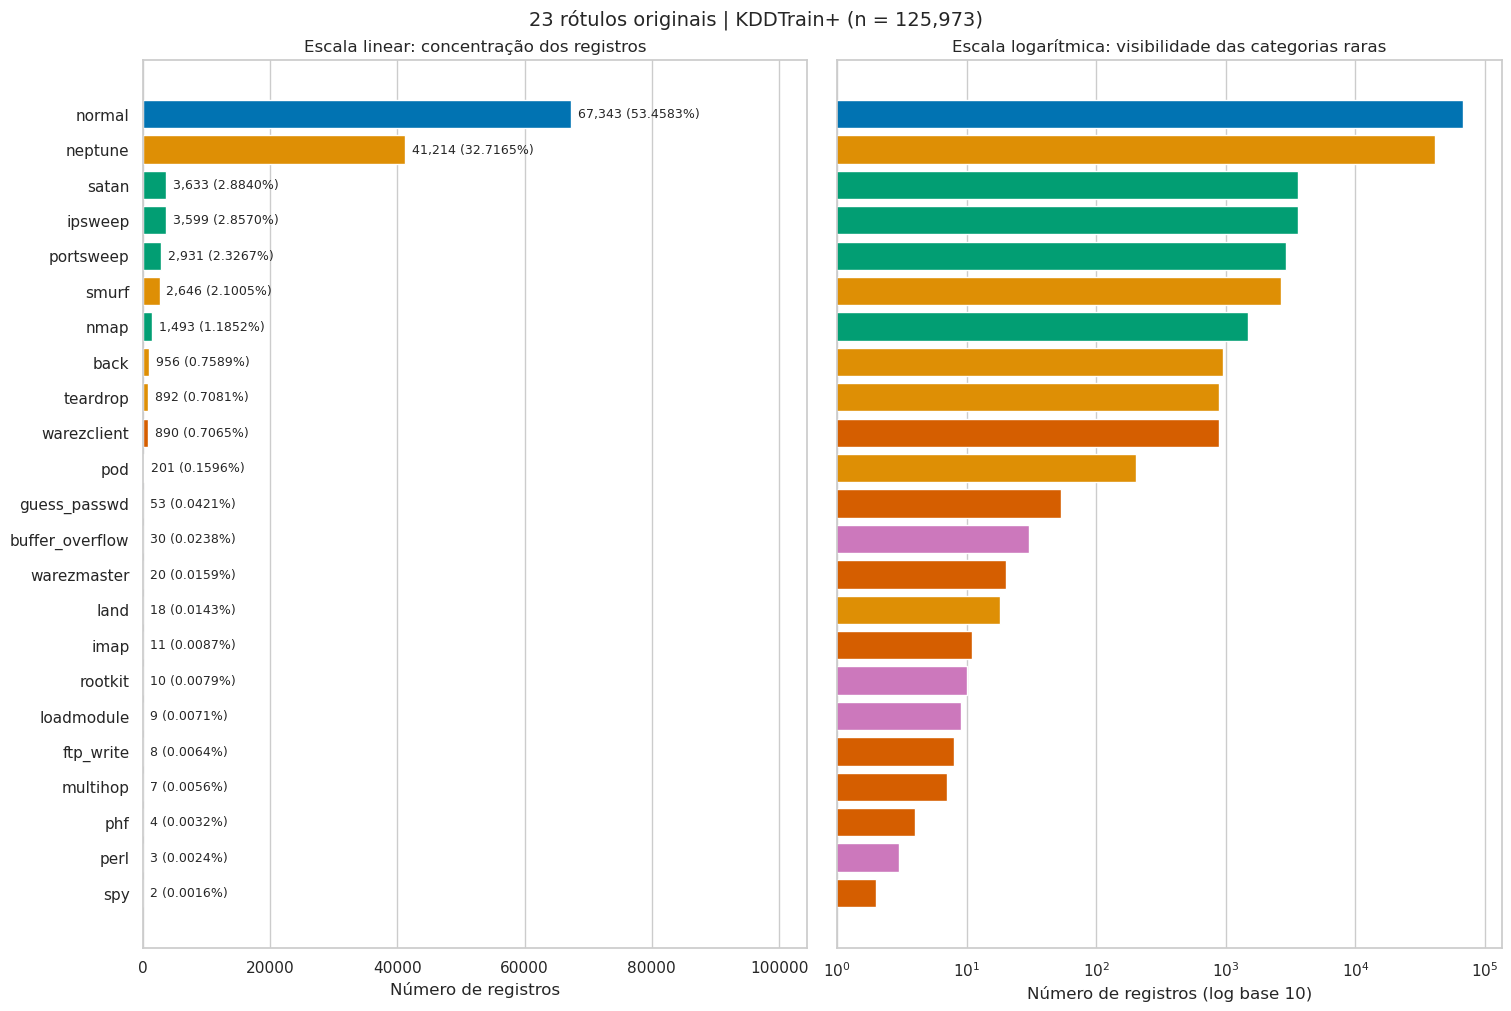

In [165]:
# As mesmas cores identificam cada família nas duas granularidades.
cores_familias = dict(zip(CLASSES_5, sns.color_palette("colorblind", len(CLASSES_5))))


def plotar_distribuicao(tabela, familias, titulo, altura):
    """Mostra frequências lineares e logarítmicas sem ocultar categorias raras."""
    fig, eixos = plt.subplots(1, 2, figsize=(15, altura), sharey=True, layout="constrained")
    posicoes = np.arange(len(tabela))
    valores = tabela["frequencia"].to_numpy()
    cores = [cores_familias[familia] for familia in familias]
    for eixo in eixos:
        eixo.barh(posicoes, valores, color=cores)
        eixo.set_yticks(posicoes, tabela.index)
        eixo.grid(axis="y", visible=False)
        eixo.set_axisbelow(True)
    eixos[0].invert_yaxis()
    eixos[0].set_xlim(0, valores.max() * 1.55)
    eixos[0].set_title("Escala linear: concentração dos registros")
    eixos[0].set_xlabel("Número de registros")
    for posicao, (quantidade, percentual) in enumerate(
        tabela[["frequencia", "percentual"]].itertuples(index=False, name=None)
    ):
        eixos[0].annotate(
            f"{quantidade:,.0f} ({percentual:.4f}%)", (quantidade, posicao),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9,
        )
    eixos[1].set_xscale("log")
    eixos[1].set_xlim(1, valores.max() * 2)
    eixos[1].set_title("Escala logarítmica: visibilidade das categorias raras")
    eixos[1].set_xlabel("Número de registros (log base 10)")
    fig.suptitle(f"{titulo} | KDDTrain+ (n = {n_treino:,})", fontsize=14)
    plt.show()


plotar_distribuicao(
    freq_rotulos, [ATTACK_MAPPING[r] for r in freq_rotulos.index],
    "23 rótulos originais", altura=10,
)

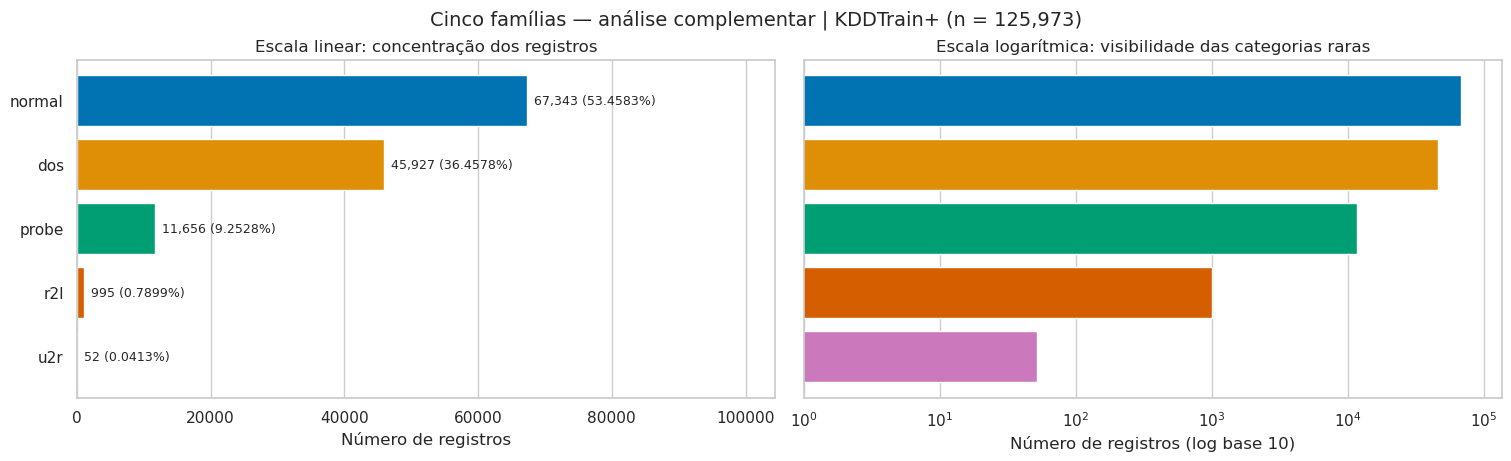

In [166]:
plotar_distribuicao(
    freq_familias, freq_familias.index,
    "Cinco famílias — análise complementar", altura=4.5,
)

### 2.4 Diagnóstico quantitativo do desbalanceamento

Quantificamos a concentração dos registros e a razão entre as maiores e menores frequências nas duas granularidades. Esses indicadores descrevem a concentração da base e a escassez de exemplos das classes raras.

In [167]:
razao_rotulos = freq_rotulos["frequencia"].max() / freq_rotulos["frequencia"].min()
razao_familias = freq_familias["frequencia"].max() / freq_familias["frequencia"].min()
pct_normal_dos = freq_familias.loc[["normal", "dos"], "percentual"].sum()

print(f"Razão maior/menor frequência original (normal/spy): {razao_rotulos:,.1f}:1")
print(f"Razão maior/menor frequência agrupada (normal/u2r): {razao_familias:,.2f}:1")
print(f"normal + dos: {pct_normal_dos:.4f}% do treino")
print(f"u2r: {freq_familias.loc['u2r', 'frequencia']:,} registros "
      f"({freq_familias.loc['u2r', 'percentual']:.4f}% do treino)")

Razão maior/menor frequência original (normal/spy): 33,671.5:1
Razão maior/menor frequência agrupada (normal/u2r): 1,295.06:1
normal + dos: 89.9161% do treino
u2r: 52 registros (0.0413% do treino)


### 2.5 Síntese do diagnóstico

O treino contém **125.973 registros e 23 rótulos originais: 22 tipos de ataque e `normal`**. A distribuição é muito desigual: `normal` tem **67.343** registros e `neptune`, **41.214**, enquanto `spy` tem **2**, `perl`, **3**, e `phf`, **4**. A razão entre o maior e o menor suporte original é **33.671,5:1**. As tabelas preservam todos os rótulos e o mapeamento cobre 100% do treino, sem rótulos ausentes ou sem correspondência.

Na análise complementar, as frequências são **normal: 67.343 (53,4583%)**, **dos: 45.927 (36,4578%)**, **probe: 11.656 (9,2528%)**, **r2l: 995 (0,7899%)** e **u2r: 52 (0,0413%)**. `normal` e `dos` concentram **89,9161%** dos registros. Há cerca de **1.295 registros normais para cada U2R**. Os 52 casos U2R são `buffer_overflow` (30), `rootkit` (10), `loadmodule` (9) e `perl` (3): a frequência agregada da família não revela, por si só, a escassez de cada tipo de ataque.

O desbalanceamento é acentuado nas duas granularidades: poucos rótulos concentram a maior parte dos registros, enquanto vários ataques têm apenas algumas ocorrências. A análise conjunta dos rótulos originais e das famílias evidencia tanto a concentração geral quanto a raridade dos tipos específicos de ataque.

---
## Membro 3: Analise dos Atributos Categoricos e Desafio da Alta Cardinalidade

**Objetivos do Membro 3:**
1. Identificar e isolar os atributos categoricos (`protocol_type`, `service` e `flag`).
2. Determinar a cardinalidade (numero de valores unicos) de cada atributo categorico.
3. Analisar em detalhe o atributo `service`, gerando a contagem dos servicos mais frequentes e dos servicos raros.
4. Discutir como lidar com categorias desconhecidas em dados futuros, sem carregar ou consultar o conjunto de teste.
5. Discutir as implicacoes da alta cardinalidade de `service` caso se utilize One-Hot Encoding puro versus tecnicas alternativas (Frequency Encoding, agrupamento de categorias raras).

### 3.1 Identificação e cardinalidade dos atributos categóricos

Analisamos os atributos `protocol_type`, `service` e `flag` exclusivamente
no conjunto de treino (`KDDTrain+`). A cardinalidade corresponde à quantidade
de categorias distintas observadas em cada atributo.

Nesta etapa, os dados são apenas analisados, sem aplicar codificações
ou alterar a base original.

In [168]:
# Seleciona os três atributos categóricos, preservando df_train.
categoricos_m3 = ["protocol_type", "service", "flag"]
dados_categoricos_m3 = df_train[categoricos_m3].copy()

cardinalidade_m3 = pd.DataFrame({"tipo": dados_categoricos_m3.dtypes.astype(str),"categorias_distintas": dados_categoricos_m3.nunique(),"valores_ausentes": dados_categoricos_m3.isna().sum(),})
cardinalidade_m3.index.name = "atributo"

display(cardinalidade_m3)

for atributo in categoricos_m3:
    categorias = sorted(dados_categoricos_m3[atributo].dropna().unique())
    print(f"\n{atributo} ({len(categorias)} categorias):")
    print(", ".join(categorias))

,tipo,categorias_distintas,valores_ausentes
atributo,,,
protocol_type,str,3,0
service,str,70,0
flag,str,11,0



protocol_type (3 categorias):
icmp, tcp, udp

service (70 categorias):
IRC, X11, Z39_50, aol, auth, bgp, courier, csnet_ns, ctf, daytime, discard, domain, domain_u, echo, eco_i, ecr_i, efs, exec, finger, ftp, ftp_data, gopher, harvest, hostnames, http, http_2784, http_443, http_8001, imap4, iso_tsap, klogin, kshell, ldap, link, login, mtp, name, netbios_dgm, netbios_ns, netbios_ssn, netstat, nnsp, nntp, ntp_u, other, pm_dump, pop_2, pop_3, printer, private, red_i, remote_job, rje, shell, smtp, sql_net, ssh, sunrpc, supdup, systat, telnet, tftp_u, tim_i, time, urh_i, urp_i, uucp, uucp_path, vmnet, whois

flag (11 categorias):
OTH, REJ, RSTO, RSTOS0, RSTR, S0, S1, S2, S3, SF, SH


### 3.2 Distribuição dos atributos categóricos

Calculamos as frequências absolutas e percentuais das categorias no conjunto
de treino. Os percentuais usam o total de registros do treino como denominador.
As tabelas permitem identificar categorias dominantes e pouco representadas.

In [169]:
# Guarda as distribuições para reutilização nas próximas análises.
frequencias_m3 = {}

for atributo in categoricos_m3:
    tabela = (dados_categoricos_m3[atributo].value_counts(dropna=False).rename_axis("categoria").to_frame("frequencia"))
    tabela["percentual"] = (tabela["frequencia"] / len(dados_categoricos_m3) * 100)
    frequencias_m3[atributo] = tabela

    # Confere se todos os registros foram contabilizados.
    assert tabela["frequencia"].sum() == len(dados_categoricos_m3)
    assert np.isclose(tabela["percentual"].sum(), 100)
    print(f"\nDistribuição de {atributo}:")
    with pd.option_context("display.max_rows", None):
        display(tabela)


Distribuição de protocol_type:


,frequencia,percentual
categoria,,
tcp,102689,81.5167
udp,14993,11.9018
icmp,8291,6.5816



Distribuição de service:


,frequencia,percentual
categoria,,
http,40338,32.0211
private,21853,17.3474
domain_u,9043,7.1785
smtp,7313,5.8052
ftp_data,6860,5.4456
eco_i,4586,3.6405
other,4359,3.4603
ecr_i,3077,2.4426
telnet,2353,1.8679



Distribuição de flag:


,frequencia,percentual
categoria,,
SF,74945,59.4929
S0,34851,27.6655
REJ,11233,8.9170
RSTR,2421,1.9218
RSTO,1562,1.2399
S1,365,0.2897
SH,271,0.2151
S2,127,0.1008
RSTOS0,103,0.0818


### 3.3 Serviços frequentes, raros e cauda longa

Analisamos a concentração dos registros nos dez serviços mais frequentes
e a presença de serviços com poucas observações.

Para este diagnóstico, consideramos raros os serviços com menos de 100
registros no treino, aproximadamente 0,08% da base por serviço. Esse limiar
é uma escolha exploratória para descrever categorias pouco representadas,
não uma regra de agrupamento já definida para o pré-processamento. A cauda longa é avaliada comparando a quantidade de categorias raras
com a proporção de registros que elas representam.

Dez serviços mais frequentes:


,frequencia,percentual
categoria,,
http,40338,32.0211
private,21853,17.3474
domain_u,9043,7.1785
smtp,7313,5.8052
ftp_data,6860,5.4456
eco_i,4586,3.6405
other,4359,3.4603
ecr_i,3077,2.4426
telnet,2353,1.8679



Serviços raros: menos de 100 registros:


,frequencia,percentual
categoria,,
rje,86,0.0683
remote_job,78,0.0619
pop_2,78,0.0619
X11,73,0.0579
printer,69,0.0548
shell,65,0.0516
urh_i,10,0.0079
tim_i,8,0.0064
red_i,8,0.0064



Os 10 serviços mais frequentes representam 80.61% dos registros.
Serviços raros: 15 de 70 categorias (21.43% das categorias).
Esses serviços somam 490 registros (0.3890% do treino).


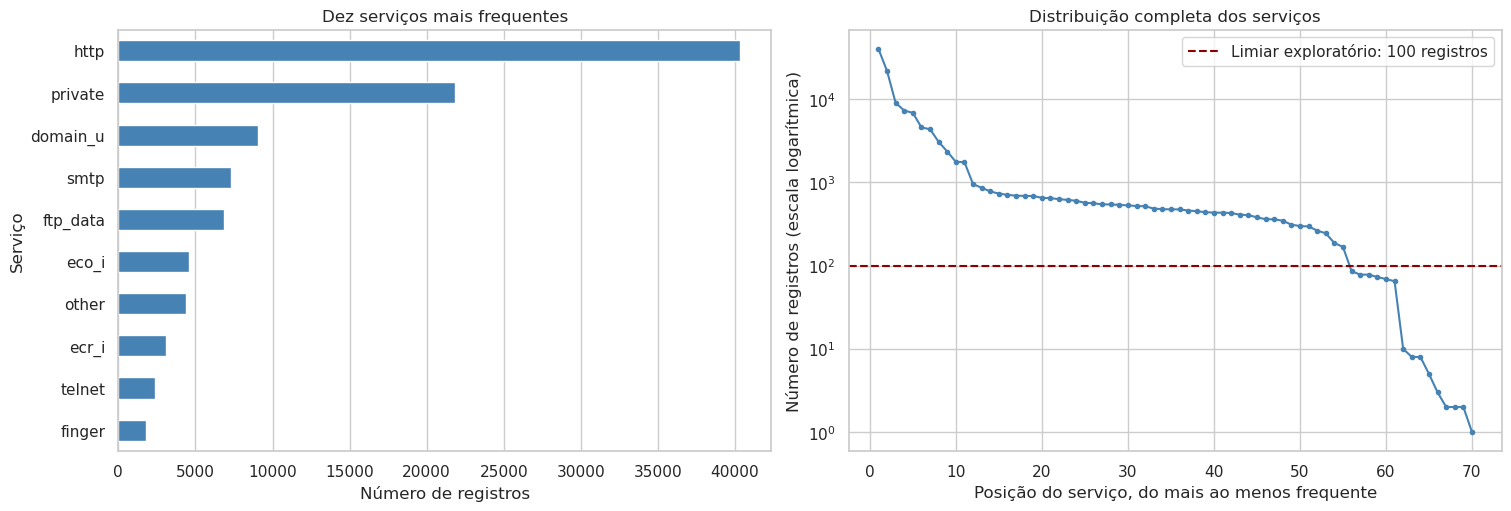

In [170]:
#Reutiliza as frequências calculadas na seção 3.2.
servicos_m3 = frequencias_m3["service"].copy()
limiar_raridade_m3 = 100
top10_m3 = servicos_m3.head(10)
raros_m3 = servicos_m3[servicos_m3["frequencia"] < limiar_raridade_m3]

print("Dez serviços mais frequentes:")
display(top10_m3)
print(f"\nServiços raros: menos de {limiar_raridade_m3} registros:")
display(raros_m3)

#quantifica a concentração e o tamanho da cauda longa
n_servicos_m3 = len(servicos_m3)
n_raros_m3 = len(raros_m3)
registros_raros_m3 = int(raros_m3["frequencia"].sum())

print(f"\nOs 10 serviços mais frequentes representam "f"{top10_m3['percentual'].sum():.2f}% dos registros.")
print(f"Serviços raros: {n_raros_m3} de {n_servicos_m3} categorias "f"({100 * n_raros_m3 / n_servicos_m3:.2f}% das categorias).")
print(f"Esses serviços somam {registros_raros_m3:,} registros "f"({raros_m3['percentual'].sum():.4f}% do treino).")

#Visualiza os serviços dominantes e a distribuição completa.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
top10_m3["frequencia"].sort_values().plot.barh(ax=eixos[0], color="steelblue")
eixos[0].set_title("Dez serviços mais frequentes")
eixos[0].set_xlabel("Número de registros")
eixos[0].set_ylabel("Serviço")
eixos[0].grid(axis="y", visible=False)
posicoes_m3 = np.arange(1, n_servicos_m3 + 1)
eixos[1].plot(posicoes_m3,servicos_m3["frequencia"].to_numpy(),marker=".",color="steelblue",)
eixos[1].axhline(limiar_raridade_m3,color="darkred",linestyle="--",label="Limiar exploratório: 100 registros",)
eixos[1].set_yscale("log")
eixos[1].set_title("Distribuição completa dos serviços")
eixos[1].set_xlabel("Posição do serviço, do mais ao menos frequente")
eixos[1].set_ylabel("Número de registros (escala logarítmica)")
eixos[1].legend()

plt.show()

Os 10 serviços mais frequentes representam 80,61% dos registros do treino, sendo que o `http` sozinho corresponde a 32,02%. Considerando raros os serviços com menos de 100 registros, encontramos 15 das 70 categorias (21,43%), mas elas somam apenas 490 conexões, ou 0,3890% do treino. Isso mostra a cauda longa da distribuição: poucos serviços aparecem muitas vezes, enquanto vários aparecem pouco. O `http_2784`, por exemplo, aparece uma única vez. Ter poucos exemplos pode dificultar o aprendizado desses serviços, mas isso não significa que eles sejam irrelevantes. Agrupar categorias raras é uma possibilidade, porém precisamos avaliar se isso causa perda de informações úteis para identificar ataques.

### 3.4 Discussão sobre alternativas de codificação e categorias desconhecidas

Os atributos analisados possuem categorias sem uma ordem natural. Por isso, substituir seus valores por números como 1, 2 e 3 pode sugerir uma ordem que não existe. O One-Hot Encoding evita isso criando uma coluna para cada categoria. Considerando as categorias observadas, seriam 84 colunas: 3 para `protocol_type`, 70 para `service` e 11 para `flag`, sem descartar categorias. Essa quantidade é viável, mas os serviços raros gerariam colunas com poucos registros de valor 1.

O Count Encoding substitui cada categoria pela sua quantidade de ocorrências, enquanto o Frequency Encoding utiliza sua frequência relativa. Essas alternativas mantêm uma coluna por atributo, mas categorias com frequências iguais recebem o mesmo valor, perdendo sua distinção. Outra possibilidade é agrupar serviços raros em uma categoria comum, reduzindo a quantidade de colunas, com o risco de juntar serviços com comportamentos diferentes. O limite de 100 registros utilizado nesta análise serve apenas para identificar raridade, sem definir um agrupamento obrigatório.

Para categorias desconhecidas em dados futuros, o One-Hot Encoding pode ser configurado para deixar todas as colunas daquele atributo com valor zero. No Count/Frequency Encoding, é possível adotar zero como valor padrão para categorias não encontradas. Também podemos definir uma categoria específica para valores desconhecidos. Em todos os casos, as categorias e frequências devem ser obtidas apenas dos dados usados para treinamento, sem utilizar informações da validação. Nesta análise, não foi necessário carregar ou consultar o `KDDTest+`.

### 3.5 Síntese da análise dos atributos categóricos

No treino, encontramos 3 categorias em `protocol_type`, 70 em `service` e 11 em `flag`, sem valores ausentes nessas colunas. O protocolo `tcp` aparece em 81,52% das conexões e a flag `SF`, em 59,49%. Já em `service`, os 10 serviços mais frequentes concentram 80,61% dos registros. Usando o critério de menos de 100 registros, encontramos 15 serviços raros, que juntos somam 490 conexões, apenas 0,3890% do treino. Essa diferença mostra que alguns serviços têm poucos exemplos disponíveis. Mesmo assim, só a frequência não é suficiente para decidir se devemos remover ou agrupar essas categorias, pois elas podem conter informações úteis para identificar ataques.

O Membro 5 pode usar `cardinalidade_m3`, `frequencias_m3` e `raros_m3` como apoio para sua análise. Essas variáveis guardam as quantidades de categorias, suas frequências e os serviços considerados raros. Ainda é preciso investigar a relação desses atributos com a classe, já que as contagens feitas aqui não mostram essa associação. Toda a análise foi feita com os dados de treino, sem alterar o `df_train` original.

---
## Membro 4: Deteccao de Redundancias, Atributos Constantes e Inconsistencias

### 4.1 Duplicatas exatas e duplicatas parciais de atributos

Aplicamos três critérios, do mais restrito ao mais amplo:
- Duplicata exata (43 colunas): linhas idênticas em todas as colunas.
- Duplicata exata sem metadado (41 atributos + 'label'): ignora 'difficulty_level', que não descreve o tráfego. Uma linha que só tenha este metadado diferente continuaria sendo o mesmo exemplo para o classificador.
- Duplicata parcial (41 atributos): mesmos atributos descritivos, mas ignorando o rótulo, quando os rótulos do grupo são diferentes temos uma inconsistência

Duplicatas importam pois dão peso extra a um mesmo exemplo na função de perda e em validação cruzada ou holdout cópias idênticas podem cair no treino e na validação ao mesmo tempo, inflando o vazamento.

In [171]:
# 4.1 Duplicatas exatas e parciais — apenas df_train (KDDTrain+), nada é alterado.
COL_ROTULO_M4 = "label"
COL_META_M4 = "difficulty_level"
ATRIB_M4 = [c for c in df_train.columns if c not in (COL_ROTULO_M4, COL_META_M4)]
n_treino_m4 = len(df_train)
assert len(ATRIB_M4) == 41, f"Esperados 41 atributos, encontrados {len(ATRIB_M4)}"

# (a) Linhas idênticas nas 43 colunas
n_dup_43 = int(df_train.duplicated().sum())

# (b) Linhas idênticas em 41 atributos + label (ignora difficulty_level)
n_dup_atrib_rotulo = int(df_train.duplicated(subset=ATRIB_M4 + [COL_ROTULO_M4]).sum())

# (c) Linhas com os mesmos 41 atributos, independentemente do rótulo.
# keep=False marca TODAS as linhas de cada grupo repetido (não só as "excedentes").
mascara_dup_parcial = df_train.duplicated(subset=ATRIB_M4, keep=False)
n_linhas_dup_parcial = int(mascara_dup_parcial.sum())
n_excedentes_dup_parcial = int(df_train.duplicated(subset=ATRIB_M4).sum())

resumo_dup_m4 = pd.DataFrame({
    "criterio": [
        "Exata: 43 colunas",
        "Exata: 41 atributos + label (ignora difficulty_level)",
        "Parcial: 41 atributos (ignora label) — todas as linhas dos grupos",
        "Parcial: 41 atributos (ignora label) — linhas excedentes",
    ],
    "n_linhas": [n_dup_43, n_dup_atrib_rotulo, n_linhas_dup_parcial, n_excedentes_dup_parcial],
})
resumo_dup_m4["pct_do_treino"] = 100 * resumo_dup_m4["n_linhas"] / n_treino_m4
display(resumo_dup_m4)

print(f"Registros no treino: {n_treino_m4:,}")
print(f"Duplicatas exatas (43 colunas): {n_dup_43}")
print(f"Duplicatas exatas sem difficulty_level: {n_dup_atrib_rotulo}")
print(f"Linhas que compartilham os 41 atributos com outra linha: {n_linhas_dup_parcial}")

# Se não há duplicata exata (atributos + label), toda repetição de atributos tem rótulos diferentes.
if n_dup_atrib_rotulo == 0:
    print("Como não há duplicata exata, todo grupo de atributos repetidos tem rótulos distintos "
          "(conflito), analisado na seção 4.2.")

,criterio,n_linhas,pct_do_treino
0,Exata: 43 colunas,0,0.0000
1,Exata: 41 atributos + label (ignora difficulty...,0,0.0000
2,Parcial: 41 atributos (ignora label) — todas a...,31,0.0246
3,Parcial: 41 atributos (ignora label) — linhas ...,16,0.0127


Registros no treino: 125,973
Duplicatas exatas (43 colunas): 0
Duplicatas exatas sem difficulty_level: 0
Linhas que compartilham os 41 atributos com outra linha: 31
Como não há duplicata exata, todo grupo de atributos repetidos tem rótulos distintos (conflito), analisado na seção 4.2.


### 4.2 Inconsistências: atributos idênticos com rótulos divergentes

Agrupamos registros com os mesmos 41 atributos e medimos o erro mínimo inevitável contando os registros fora da classe mais frequente de cada grupo.

Os conflitos são analisados com 23 rótulos originais e 5 famílias de ataques. Conflitos entre ataques da mesma família, como ipsweep e nmap (probe), desaparecem na análise por famílias.

In [172]:
# 4.2 Conflitos de rótulo: mesmos 41 atributos, rótulos diferentes.
sub_dup_m4 = df_train.loc[mascara_dup_parcial, ATRIB_M4 + [COL_ROTULO_M4]].copy()
sub_dup_m4["familia"] = sub_dup_m4[COL_ROTULO_M4].map(ATTACK_MAPPING)
assert sub_dup_m4["familia"].notna().all(), "Rótulo sem mapeamento em ATTACK_MAPPING"

def _maior_contagem(s):
    return int(s.value_counts().iloc[0])

grupos_m4 = (
    sub_dup_m4.groupby(ATRIB_M4, sort=False, dropna=False)
    .agg(
        n_registros=(COL_ROTULO_M4, "size"),
        n_rotulos=(COL_ROTULO_M4, "nunique"),
        n_familias=("familia", "nunique"),
        rotulos=(COL_ROTULO_M4, lambda s: " | ".join(sorted(s.unique()))),
        maior_rotulo=(COL_ROTULO_M4, _maior_contagem),
        maior_familia=("familia", _maior_contagem),
    )
    .reset_index()
)

def _tipo_conflito(linha):
    if linha["n_rotulos"] == 1:
        return "sem conflito"
    if "normal" in linha["rotulos"].split(" | "):
        return "normal x ataque"
    if linha["n_familias"] == 1:
        return "ataque x ataque (mesma família)"
    return "ataque x ataque (famílias distintas)"

grupos_m4["tipo_conflito"] = grupos_m4.apply(_tipo_conflito, axis=1)
conflitos_m4 = grupos_m4[grupos_m4["n_rotulos"] > 1].copy()
conflitos_familia_m4 = conflitos_m4[conflitos_m4["n_familias"] > 1]

n_grupos_repetidos = len(grupos_m4)
n_grupos_conflito = len(conflitos_m4)
n_linhas_conflito = int(conflitos_m4["n_registros"].sum())
erro_min_rotulos = int((conflitos_m4["n_registros"] - conflitos_m4["maior_rotulo"]).sum())
erro_min_familias = int((conflitos_m4["n_registros"] - conflitos_m4["maior_familia"]).sum())

print(f"Grupos de atributos repetidos: {n_grupos_repetidos}")
print(f"Grupos com rótulos divergentes: {n_grupos_conflito} ({n_linhas_conflito} linhas, "
      f"{100 * n_linhas_conflito / n_treino_m4:.4f}% do treino)")
print(f"Grupos que continuam em conflito na visão de 5 famílias: {len(conflitos_familia_m4)}")
print(f"Erro mínimo inevitável (resubstituição): {erro_min_rotulos} registros nos 23 rótulos "
      f"({100 * erro_min_rotulos / n_treino_m4:.4f}% do treino); "
      f"{erro_min_familias} nas 5 famílias ({100 * erro_min_familias / n_treino_m4:.4f}%)")

print("\nTipos de conflito (grupos e linhas):")
display(conflitos_m4.groupby("tipo_conflito").agg(
    grupos=("n_registros", "size"), linhas=("n_registros", "sum")))

print("Conflitos por protocolo (grupos):")
display(conflitos_m4["protocol_type"].value_counts().rename("grupos").to_frame())

print("Grupos em conflito:")
with pd.option_context("display.max_colwidth", None, "display.width", 220):
    display(conflitos_m4.sort_values(["protocol_type", "service", "flag", "src_bytes"])[
        ["protocol_type", "service", "flag", "src_bytes", "dst_bytes",
         "n_registros", "rotulos", "tipo_conflito"]].reset_index(drop=True))

# Quanto cada classe perderia se as linhas conflitantes fossem removidas
linhas_conflito_m4 = sub_dup_m4.merge(conflitos_m4[ATRIB_M4], on=ATRIB_M4, how="inner")
afetados_m4 = linhas_conflito_m4[COL_ROTULO_M4].value_counts().rename("linhas_em_conflito").to_frame()
afetados_m4["total_no_treino"] = df_train[COL_ROTULO_M4].value_counts().reindex(afetados_m4.index)
afetados_m4["pct_da_classe"] = 100 * afetados_m4["linhas_em_conflito"] / afetados_m4["total_no_treino"]
assert len(linhas_conflito_m4) == n_linhas_conflito
print("Classes afetadas e parcela de cada classe envolvida em conflito:")
display(afetados_m4.sort_values("pct_da_classe", ascending=False))

Grupos de atributos repetidos: 15
Grupos com rótulos divergentes: 15 (31 linhas, 0.0246% do treino)
Grupos que continuam em conflito na visão de 5 famílias: 7
Erro mínimo inevitável (resubstituição): 16 registros nos 23 rótulos (0.0127% do treino); 7 nas 5 famílias (0.0056%)

Tipos de conflito (grupos e linhas):


,grupos,linhas
tipo_conflito,,
ataque x ataque (mesma família),8,17
normal x ataque,7,14


Conflitos por protocolo (grupos):


,grupos
protocol_type,
icmp,10
tcp,4
udp,1


Grupos em conflito:


,protocol_type,service,flag,src_bytes,dst_bytes,n_registros,rotulos,tipo_conflito
0,icmp,eco_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
1,icmp,eco_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
2,icmp,eco_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
3,icmp,eco_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
4,icmp,ecr_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
5,icmp,ecr_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
6,icmp,ecr_i,SF,8,0,3,ipsweep | nmap | portsweep,ataque x ataque (mesma família)
7,icmp,ecr_i,SF,8,0,2,ipsweep | nmap,ataque x ataque (mesma família)
8,icmp,ecr_i,SF,20,0,2,normal | satan,normal x ataque
9,icmp,tim_i,SF,564,0,2,normal | pod,normal x ataque


Classes afetadas e parcela de cada classe envolvida em conflito:


,linhas_em_conflito,total_no_treino,pct_da_classe
label,,,
land,4,18,22.2222
rootkit,1,10,10.0000
nmap,8,1493,0.5358
pod,1,201,0.4975
ipsweep,8,3599,0.2223
portsweep,1,2931,0.0341
satan,1,3633,0.0275
normal,7,67343,0.0104


### 4.3 Atributos constantes (variância zero)

Um atributo constante tem variância zero, ou seja, apresenta o mesmo valor em todas as linhas e não ajuda a distinguir classes. Além disso, pode causar problemas em normalizações.

Verificamos isso contando os valores únicos nos 41 atributos e calculando o desvio padrão dos numéricos. Também buscamos colunas idênticas para identificar atributos redundantes.

In [173]:
# 4.3 Atributos constantes (variância zero) e colunas idênticas entre si.

numericas_m4 = df_train[ATRIB_M4].select_dtypes(include="number").columns.tolist()

perfil_var_m4 = pd.DataFrame({
    "n_valores_unicos": df_train[ATRIB_M4].nunique(),
    "desvio_padrao": df_train[numericas_m4].std(),      # NaN nos categóricos
    "variancia": df_train[numericas_m4].var(),
})

constantes_unicos = set(perfil_var_m4.index[perfil_var_m4["n_valores_unicos"] == 1])
constantes_std = set(perfil_var_m4.index[perfil_var_m4["desvio_padrao"] == 0])
assert constantes_std <= constantes_unicos, "Divergência entre os dois critérios"
constantes_m4 = sorted(constantes_unicos)

print(f"Atributos com 1 único valor (nos 41): {constantes_m4}")
print(f"Atributos numéricos com desvio padrão = 0: {sorted(constantes_std)}")
if constantes_m4:
    display(pd.DataFrame({
        "valor_unico": [df_train[c].iloc[0] for c in constantes_m4],
        "n_registros": n_treino_m4,
    }, index=constantes_m4))

print("\nAtributos com menos valores distintos:")
display(perfil_var_m4.sort_values("n_valores_unicos").head(8))

# Colunas idênticas entre si (redundância exata de atributos)
pares_identicos_m4 = [(a, b) for a, b in combinations(ATRIB_M4, 2)
                      if df_train[a].equals(df_train[b])]
print(f"\nPares de colunas idênticas entre os 41 atributos: {len(pares_identicos_m4)}")
for a, b in pares_identicos_m4:
    print(f"  {a} == {b}")

Atributos com 1 único valor (nos 41): ['num_outbound_cmds']
Atributos numéricos com desvio padrão = 0: ['num_outbound_cmds']


,valor_unico,n_registros
num_outbound_cmds,0,125973



Atributos com menos valores distintos:


,n_valores_unicos,desvio_padrao,variancia
num_outbound_cmds,1,0.0000,0.0000
root_shell,2,0.0366,0.0013
logged_in,2,0.4890,0.2391
land,2,0.0141,0.0002
is_host_login,2,0.0028,0.0000
is_guest_login,2,0.0966,0.0093
wrong_fragment,3,0.2535,0.0643
su_attempted,3,0.0452,0.0020



Pares de colunas idênticas entre os 41 atributos: 0


### 4.4 Atributos quase constantes, concentração em zero e domínio de 'su_attempted'

No NSL-KDD, muitos atributos têm valores concentrados em zero, para identificá-los, usamos dois indicadores exploratórios:

- Valor dominante: quase constante (≥ 99%) ou concentrado (90% a 99%).

- Zeros: atributos com pelo menos 75% de zeros.

Testamos o nearZeroVar do pacote caret, mas ele marcou atributos que não são quase constantes, como dst_bytes e same_srv_rate e por isso preferimos o percentual do valor dominante.

Valores raros podem indicar ataques pouco frequentes, como r2l e u2r. Assim, comparamos a proporção de ataques nesses registros com a taxa geral de 46,54%. Essa análise é descritiva; a associação com a classe será estudada pelo Membro 5.

Por fim, verificamos que su_attempted, definido como binário, também assume o valor 2 nos dados de treino.

In [174]:
# 4.4 Quase constantes, concentração em zero e domínio de su_attempted.
LIMIAR_DOMINANTE_M4 = 99.0     # quase constante: >= 99% dos registros no mesmo valor
LIMIAR_CONCENTRADO_M4 = 90.0   # concentrado: entre 90% e 99% no mesmo valor
LIMIAR_ZEROS_M4 = 75.0         # apenas para listar atributos muito concentrados em zero

def perfil_concentracao(serie):
    contagem = serie.value_counts()
    freq1 = int(contagem.iloc[0])
    return {
        "valor_dominante": contagem.index[0],
        "pct_dominante": 100 * freq1 / len(serie),
        "n_fora_do_dominante": len(serie) - freq1,
    }

conc_m4 = pd.DataFrame([{"atributo": c, **perfil_concentracao(df_train[c])} for c in ATRIB_M4]).set_index("atributo")
conc_m4["pct_zeros"] = (df_train[numericas_m4] == 0).mean() * 100      # NaN nos categóricos

eh_constante = conc_m4["n_fora_do_dominante"] == 0
eh_q99 = conc_m4["pct_dominante"] >= LIMIAR_DOMINANTE_M4
eh_conc = conc_m4["pct_dominante"] >= LIMIAR_CONCENTRADO_M4
conc_m4["categoria"] = np.select(
    [eh_constante, eh_q99, eh_conc],
    ["constante", "quase constante (>= 99% no mesmo valor)", "concentrado (90% a 99% no mesmo valor)"],
    default="sem concentração relevante",
)

candidatos_nzv_m4 = conc_m4.index[~conc_m4["categoria"].isin(["constante", "sem concentração relevante"])].tolist()

print(conc_m4["categoria"].value_counts().to_string())
print(f"\nAtributos com >= {LIMIAR_ZEROS_M4:.0f}% de zeros: {int((conc_m4['pct_zeros'] >= LIMIAR_ZEROS_M4).sum())}")

mostrar_m4 = conc_m4[(conc_m4["categoria"] != "sem concentração relevante")
                     | (conc_m4["pct_zeros"] >= LIMIAR_ZEROS_M4)]
display(mostrar_m4.sort_values("pct_dominante", ascending=False))

eh_ataque_m4 = df_train[COL_ROTULO_M4] != "normal"
base_ataque_m4 = 100 * eh_ataque_m4.mean()
linhas_sinal = []
for c in candidatos_nzv_m4:
    fora = df_train[c] != conc_m4.loc[c, "valor_dominante"]
    rotulos_fora = df_train.loc[fora, COL_ROTULO_M4].value_counts(normalize=True)
    linhas_sinal.append({
        "atributo": c,
        "n_fora_do_dominante": int(fora.sum()),
        "pct_ataque_fora_do_dominante": 100 * eh_ataque_m4[fora].mean(),
        "rotulo_mais_comum_fora": rotulos_fora.index[0],
        "pct_desse_rotulo_fora": 100 * rotulos_fora.iloc[0],
    })
sinal_nzv_m4 = pd.DataFrame(linhas_sinal).set_index("atributo")
print(f"\nBase inteira: {base_ataque_m4:.2f}% dos registros são ataques.")
display(sinal_nzv_m4.sort_values("n_fora_do_dominante"))

# Domínio de su_attempted
dist_su_m4 = df_train["su_attempted"].value_counts().sort_index().rename("frequencia").to_frame()
dist_su_m4["percentual"] = 100 * dist_su_m4["frequencia"] / n_treino_m4
n_su_fora_dominio = int((~df_train["su_attempted"].isin([0, 1])).sum())
print("\nDistribuição de su_attempted:")
display(dist_su_m4)
print(f"Registros com su_attempted fora de {{0, 1}}: {n_su_fora_dominio}")
if n_su_fora_dominio:
    display(df_train.loc[~df_train["su_attempted"].isin([0, 1]), COL_ROTULO_M4]
            .value_counts().rename("registros_com_su_attempted_fora_do_dominio").to_frame())

categoria
sem concentração relevante                 25
quase constante (>= 99% no mesmo valor)    12
concentrado (90% a 99% no mesmo valor)      3
constante                                   1

Atributos com >= 75% de zeros: 21


,valor_dominante,pct_dominante,n_fora_do_dominante,pct_zeros,categoria
atributo,,,,,
num_outbound_cmds,0,100.0000,0,100.0000,constante
is_host_login,0,99.9992,1,99.9992,quase constante (>= 99% no mesmo valor)
urgent,0,99.9929,9,99.9929,quase constante (>= 99% no mesmo valor)
land,0,99.9802,25,99.9802,quase constante (>= 99% no mesmo valor)
num_shells,0,99.9627,47,99.9627,quase constante (>= 99% no mesmo valor)
su_attempted,0,99.9365,80,99.9365,quase constante (>= 99% no mesmo valor)
num_failed_logins,0,99.9032,122,99.9032,quase constante (>= 99% no mesmo valor)
root_shell,0,99.8658,169,99.8658,quase constante (>= 99% no mesmo valor)
num_file_creations,0,99.7722,287,99.7722,quase constante (>= 99% no mesmo valor)



Base inteira: 46.54% dos registros são ataques.


,n_fora_do_dominante,pct_ataque_fora_do_dominante,rotulo_mais_comum_fora,pct_desse_rotulo_fora
atributo,,,,
is_host_login,1,0.0000,normal,100.0000
urgent,9,33.3333,normal,66.6667
land,25,72.0000,land,72.0000
num_shells,47,17.0213,normal,82.9787
su_attempted,80,1.2500,normal,98.7500
num_failed_logins,122,44.2623,normal,55.7377
root_shell,169,18.9349,normal,81.0651
num_file_creations,287,11.8467,normal,88.1533
num_access_files,371,2.6954,normal,97.3046



Distribuição de su_attempted:


,frequencia,percentual
su_attempted,,
0,125893,99.9365
1,21,0.0167
2,59,0.0468


Registros com su_attempted fora de {0, 1}: 59


,registros_com_su_attempted_fora_do_dominio
label,
normal,59


### 4.5 Decisões propostas para o pré-processamento

Remoção e tratamento seguem estas regras: 

- Remover: atributos que não apresentam nenhuma variação.

- Tratar: atributos com valores inválidos, como su_attempted.

- Quase constantes: avaliar a remoção de atributos com menos de 30 valores diferentes do dominante e sem mais ataques que a média da base. A decisão será confirmada na Etapa 2, comparando os resultados com e sem o atributo. Os demais serão mantidos, como land.

- Rótulos conflitantes: manter os registros e considerar os conflitos como ruídos da base.

In [175]:
# 4.5 Tabela de decisões para a Etapa 2 (gerada a partir dos resultados acima).
LIMIAR_SUPORTE_M4 = 30   # exploratório: < 30 registros fora do valor dominante

decisoes = []

for c in constantes_m4:
    decisoes.append({
        "alvo": c, "tipo": "coluna", "decisao": "Descartar",
        "justificativa": f"Variância zero: valor único {df_train[c].iloc[0]} em {n_treino_m4:,} registros. "
                         f"Não discrimina nenhuma classe."})

if n_su_fora_dominio:
    rotulos_su = df_train.loc[~df_train["su_attempted"].isin([0, 1]), COL_ROTULO_M4].value_counts()
    resumo_rotulos_su = ", ".join(f"{r}: {n}" for r, n in rotulos_su.items())
    decisoes.append({
        "alvo": "su_attempted", "tipo": "coluna (domínio)", "decisao": "Tratar",
        "justificativa": f"Documentado como binário, mas {n_su_fora_dominio} registros valem 2 "
                         f"(rótulos: {resumo_rotulos_su}). Binarizar (valor > 0 vira 1), "
                         f"regra sem parâmetros aprendidos."})

ja_decididos = {"su_attempted"}
for c in candidatos_nzv_m4:
    if c in ja_decididos:
        continue
    n_fora = int(conc_m4.loc[c, "n_fora_do_dominante"])
    pct_atq = sinal_nzv_m4.loc[c, "pct_ataque_fora_do_dominante"]
    if n_fora < LIMIAR_SUPORTE_M4 and pct_atq <= base_ataque_m4:
        decisao = "Candidato a remoção (validar na Etapa 2)"
        just = (f"Só {n_fora} registro(s) fora do valor dominante ({conc_m4.loc[c, 'pct_dominante']:.4f}%), "
                f"com {pct_atq:.1f}% de ataques (base: {base_ataque_m4:.1f}%): sem suporte nem sinal de ataque. "
                f"Comparar desempenho com e sem o atributo.")
    elif n_fora < LIMIAR_SUPORTE_M4:
        decisao = "Manter (poucos registros, mas com sinal de ataque)"
        just = (f"Só {n_fora} registros fora do valor dominante, porém {pct_atq:.1f}% são ataques "
                f"(base: {base_ataque_m4:.1f}%; rótulo mais comum: {sinal_nzv_m4.loc[c, 'rotulo_mais_comum_fora']}). "
                f"Removê-lo apagaria evidência de uma classe rara.")
    else:
        decisao = "Manter (monitorar)"
        just = (f"{n_fora} registros fora do valor dominante ({conc_m4.loc[c, 'pct_dominante']:.4f}%). "
                f"O valor raro pode sinalizar ataques raros; não descartar sem evidência.")
    decisoes.append({"alvo": c, "tipo": "coluna", "decisao": decisao, "justificativa": just})

decisoes.append({
    "alvo": "duplicatas exatas", "tipo": "registros",
    "decisao": "Nenhuma remoção" if n_dup_43 == 0 and n_dup_atrib_rotulo == 0 else "Remover do treino",
    "justificativa": f"{n_dup_43} duplicatas nas 43 colunas e {n_dup_atrib_rotulo} ignorando difficulty_level. "
                     f"Se houver deduplicação no pipeline, aplicar só ao treino, antes de dividir em dobras."})

decisoes.append({
    "alvo": "conflitos de rótulo", "tipo": "registros", "decisao": "Manter e documentar",
    "justificativa": f"{n_grupos_conflito} grupos / {n_linhas_conflito} linhas "
                     f"({100 * n_linhas_conflito / n_treino_m4:.4f}% do treino). Removê-los reduziria classes raras "
                     f"e tornaria a estimativa otimista; reetiquetar por maioria inventaria rótulos. "
                     f"Erro mínimo inevitável: {erro_min_rotulos} (23 rótulos) / {erro_min_familias} (5 famílias)."})

decisoes_m4 = pd.DataFrame(decisoes)
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(decisoes_m4)

colunas_descartar_m4 = [d["alvo"] for d in decisoes if d["decisao"] == "Descartar"]
print("Colunas a descartar (variância zero):", colunas_descartar_m4)

,alvo,tipo,decisao,justificativa
0,num_outbound_cmds,coluna,Descartar,"Variância zero: valor único 0 em 125,973 registros. Não discrimina nenhuma classe."
1,su_attempted,coluna (domínio),Tratar,"Documentado como binário, mas 59 registros valem 2 (rótulos: normal: 59). Binarizar (valor > 0 vira 1), regra sem parâmetros aprendidos."
2,duration,coluna,Manter (monitorar),10018 registros fora do valor dominante (92.0475%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.
3,land,coluna,"Manter (poucos registros, mas com sinal de ataque)","Só 25 registros fora do valor dominante, porém 72.0% são ataques (base: 46.5%; rótulo mais comum: land). Removê-lo apagaria evidência de uma classe rara."
4,wrong_fragment,coluna,Manter (monitorar),1090 registros fora do valor dominante (99.1347%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.
5,urgent,coluna,Candidato a remoção (validar na Etapa 2),"Só 9 registro(s) fora do valor dominante (99.9929%), com 33.3% de ataques (base: 46.5%): sem suporte nem sinal de ataque. Comparar desempenho com e sem o atributo."
6,hot,coluna,Manter (monitorar),2671 registros fora do valor dominante (97.8797%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.
7,num_failed_logins,coluna,Manter (monitorar),122 registros fora do valor dominante (99.9032%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.
8,num_compromised,coluna,Manter (monitorar),1286 registros fora do valor dominante (98.9791%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.
9,root_shell,coluna,Manter (monitorar),169 registros fora do valor dominante (99.8658%). O valor raro pode sinalizar ataques raros; não descartar sem evidência.


Colunas a descartar (variância zero): ['num_outbound_cmds']


### 4.6 Síntese do Membro 4

Duplicatas e rótulos conflitantes: Não foram encontradas duplicatas no treino. Porém, há 15 grupos (31 registros) com os mesmos atributos e rótulos diferentes, esses casos serão mantidos e documentados como ruído da base, pois removê-los ou alterar seus rótulos poderia prejudicar a análise, principalmente de classes raras.

Atributos constantes: num_outbound_cmds apresenta apenas o valor zero em todos os registros e por isso, será removido na Etapa 2, usando apenas os dados de treino.

Atributos quase constantes: Apesar da grande concentração de zeros em vários atributos, valores raros podem ajudar a identificar ataques específicos. Assim, is_host_login e urgent serão avaliados para possível remoção na Etapa 2, comparando o desempenho com e sem eles. O atributo land e os demais serão mantidos.

Tratamento de su_attempted: Como esse atributo deveria ser binário, mas também apresenta o valor 2, será feita a binarização: valores maiores que zero serão convertidos em 1. Essa regra será aplicada ao treino e ao teste.

Resumo das decisões: Remover num_outbound_cmds, tratar su_attempted, manter os registros conflitantes e avaliar a remoção de is_host_login e urgent. A análise utilizou apenas o KDDTrain+, sem alterar os dados originais nem consultar o conjunto de teste, evitando vazamento de dados.

---
## Membro 5: Investigacao de Vazamento de Dados (Data Leakage) e Diagnostico Final

**Objetivos do Membro 5:**
1. Analisar criticamente a coluna `difficulty_level`, demonstrando sua relacao com a classe e justificando por que ela NAO deve ser incluida como feature descritiva nos modelos.
2. Avaliar correlacao linear (ou associacao estatistica) entre as features numericas e a classe, verificando atributos que apresentem associacao suspeita ou espuria.
3. Verificar a correlacao entre atributos para identificar multicolinearidade severa.
4. Consolidar os apontamentos dos 5 membros em uma secao conclusiva de Diagnostico Geral dos Dados para submissao da Etapa 1.

In [176]:
# TODO Membro 5: Analise da coluna difficulty_level e justificativa contra data leakage
# Implemente aqui a inspecao de difficulty_level por classe e demonstracao do risco metodologico

In [177]:
# TODO Membro 5: Analise de correlacao de atributos com a classe e multicolinearidade
# Implemente aqui a matriz de correlacao ou analise de correlacao com o target

### Sintese do Membro 5 e Diagnostico Consolidado da Etapa 1
*[Espaco para o Membro 5 redigir a conclusao sobre prevencao de data leakage e consolidar o diagnostico geral da equipe para entrega]*